# 01 · Logistic Regression and Decision Analysis
Predict student depression risk and evaluate how predictions can be used to prioritize counseling outreach under limited capacity.

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

## Load Data

In [2]:
df = pd.read_csv('../data/Student_Depression_Dataset.csv')

## Data Preparation
- Encode the target `Depression` as `is_depressed` (1 = Yes, 0 = No).
- Exclude `Health_condition`: the label is largely determined by this feature (see `00_data_check.ipynb`).
- One-hot encode categorical features with the first category as the reference level.
- Rescale `Cost_without_study` to thousands of local currency units, likely BDT (`Cost_k`), for interpretable odds ratios.
- Set `In a Relationship` as the reference level for `Relationship_status`.

In [3]:
df['is_depressed'] = (df['Depression'] == 'Yes').astype(int)
df = df.drop(columns=['Depression', 'Health_condition'])
df['Cost_k'] = df['Cost_without_study'] / 1000
df = df.drop(columns='Cost_without_study')

In [4]:
df['Relationship_status'] = pd.Categorical(
    df['Relationship_status'],
    categories=['In a Relationship', 'Single', 'Complicated']
)

In [5]:
df_model = pd.get_dummies(df, drop_first=True, dtype=float)
df_model.columns.tolist()

['Age',
 'Current_semester',
 'CGPA',
 'is_depressed',
 'Cost_k',
 'Gender_Male',
 'Family_background_Middle class',
 'Family_background_Rich class',
 'Relationship_status_Single',
 'Relationship_status_Complicated',
 'Marital_status_Separated',
 'Marital_status_Unmarried',
 'Living_style_Family',
 'friend_circle_Yes',
 'Home_division_Chittagong',
 'Home_division_Dhaka',
 'Home_division_Khulna',
 'Home_division_Mymensingh',
 'Home_division_Rajshahi',
 'Home_division_Rangpur',
 'Home_division_Sylhet']

## Train/Test Split
70/30 split, stratified on the target to preserve the class ratio.

In [6]:
X = df_model.drop(columns='is_depressed')
y = df_model['is_depressed']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print('Train:', X_train.shape, '| Depression rate:', round(y_train.mean(), 4))
print('Test: ', X_test.shape, '| Depression rate:', round(y_test.mean(), 4))

Train: (3124, 20) | Depression rate: 0.2689
Test:  (1340, 20) | Depression rate: 0.2694


## Baseline Accuracy
Always predict the majority class (determined from the training set), evaluated on the test set.

In [8]:
majority_class = int(y_train.mean() >= 0.5)
baseline_acc = (y_test == majority_class).mean()

In [9]:
print('Majority class:', majority_class)
print('Baseline accuracy (test):', round(baseline_acc, 4))

Majority class: 0
Baseline accuracy (test): 0.7306


## Logistic Regression (statsmodels GLM)
Fit a binomial GLM with logit link on the training set.

In [10]:
X_train_c = sm.add_constant(X_train)
X_test_c = sm.add_constant(X_test)

model = sm.GLM(y_train, X_train_c, family=sm.families.Binomial())
res = model.fit()
print(res.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:           is_depressed   No. Observations:                 3124
Model:                            GLM   Df Residuals:                     3103
Model Family:                Binomial   Df Model:                           20
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1588.1
Date:                Wed, 11 Nov 2026   Deviance:                       3176.2
Time:                        14:43:37   Pearson chi2:                 3.05e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1372
Covariance Type:            nonrobust                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

## Odds Ratios
OR = exp(coefficient). For a dummy variable, OR is the multiplicative change in the odds of depression relative to the reference level, holding other variables constant.

In [11]:
or_table = pd.DataFrame({
    'coef': res.params,
    'odds_ratio': np.exp(res.params),
    'OR_ci_lower': np.exp(res.conf_int()[0]),
    'OR_ci_upper': np.exp(res.conf_int()[1]),
    'p_value': res.pvalues
}).round(4)

or_table.sort_values('odds_ratio', ascending=False)

,coef,odds_ratio,OR_ci_lower,OR_ci_upper,p_value
Relationship_status_Single,1.6260,5.0834,3.9924,6.4725,0.0000
Marital_status_Unmarried,0.7173,2.0488,1.4975,2.8031,0.0000
Marital_status_Separated,0.5833,1.7919,0.9353,3.4330,0.0787
Home_division_Chittagong,0.2694,1.3091,0.8811,1.9451,0.1824
Home_division_Rajshahi,0.2692,1.3089,0.8848,1.9361,0.1778
Home_division_Khulna,0.2403,1.2716,0.8749,1.8481,0.2079
Home_division_Rangpur,0.1061,1.1119,0.7341,1.6842,0.6165
Cost_k,0.0679,1.0703,1.0491,1.0919,0.0000
Living_style_Family,0.0486,1.0498,0.8560,1.2876,0.6406
Relationship_status_Complicated,0.0314,1.0319,0.5869,1.8142,0.9131


### Interpretation
Holding other variables constant:
- **CGPA**: each 1-point increase in CGPA multiplies the odds of depression by 0.49 (a 51% decrease).
- **Family background**: students from rich families have 0.23 times the odds of depression compared with lower-middle-class students (a 77% decrease).
- **Gender**: male students have 0.58 times the odds of female students (a 42% decrease).
- **Friend circle**: having an active friend circle multiplies the odds by 0.67 (a 33% decrease).
- **Living cost**: each additional 1,000 units of living cost (local currency, likely BDT) multiplies the odds by 1.07 (a 7% increase).
- **Relationship status**: single students have 5.08 times the odds of students in a relationship. Students in a *complicated* relationship do not differ significantly from those in a relationship (p = 0.91).
- **Marital status**: unmarried students have 2.05 times the odds of married students.

`Age`, `Current_semester`, `Living_style`, and `Home_division` are not significant at the 5% level.

## Prediction for a Single Student
Compute logit, odds, and probability by hand for one test-set student and verify against `res.predict()`.
- logit = Xβ
- odds = exp(logit)
- probability = odds / (1 + odds)

In [12]:
x_i = X_test_c.iloc[[0]]

In [13]:
logit_i = (x_i @ res.params).item()
odds_i = np.exp(logit_i)
prob_i = odds_i / (1 + odds_i)

In [14]:
print('Logit:      ', round(logit_i, 4))
print('Odds:       ', round(odds_i, 4))
print('Probability:', round(prob_i, 4))
print('res.predict:', round(res.predict(x_i).item(), 4))
print('Actual label:', y_test.iloc[0])

Logit:       -0.9149
Odds:        0.4005
Probability: 0.286
res.predict: 0.286
Actual label: 0


This student's predicted probability of depression is 0.286, slightly above the training base rate of 0.269. At a 0.5 threshold, the model predicts *not depressed*, which matches the actual label.

## Confusion Matrix (Threshold = 0.5)

In [15]:
from sklearn.metrics import confusion_matrix

In [16]:
pred_prob_test = res.predict(X_test_c)
pred_test = (pred_prob_test >= 0.5).astype(int)

In [17]:
cm = confusion_matrix(y_test, pred_test)
tn, fp, fn, tp = cm.ravel()

In [18]:
pd.DataFrame(cm,
             index=['Actual: No', 'Actual: Yes'],
             columns=['Predicted: No', 'Predicted: Yes'])

,Predicted: No,Predicted: Yes
Actual: No,907,72
Actual: Yes,291,70


In [19]:
accuracy  = (tp + tn) / (tp + tn + fp + fn)
tpr       = tp / (tp + fn)   # recall / sensitivity
fpr       = fp / (fp + tn)
precision = tp / (tp + fp)

In [20]:
print('Accuracy: ', round(accuracy, 4), '| Baseline:', round(baseline_acc, 4))
print('TPR:      ', round(tpr, 4))
print('FPR:      ', round(fpr, 4))
print('Precision:', round(precision, 4))

Accuracy:  0.7291 | Baseline: 0.7306
TPR:       0.1939
FPR:       0.0735
Precision: 0.493


At a 0.5 threshold, the model's accuracy (0.729) is slightly *below* the baseline of always predicting "not depressed" (0.731). It identifies only 19% of depressed students (TPR = 0.19), because with a 27% base rate most predicted probabilities fall below 0.5.

Accuracy at a single threshold does not reflect the model's ability to rank students by risk. The next sections evaluate ranking quality (ROC/AUC) and choose a threshold based on the costs of false positives and false negatives.

## ROC Curve and AUC
The ROC curve plots TPR against FPR across all thresholds. AUC is the probability that a randomly chosen depressed student receives a higher predicted probability than a randomly chosen non-depressed student.

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

In [22]:
fpr_curve, tpr_curve, thresholds = roc_curve(y_test, pred_prob_test)
auc = roc_auc_score(y_test, pred_prob_test)

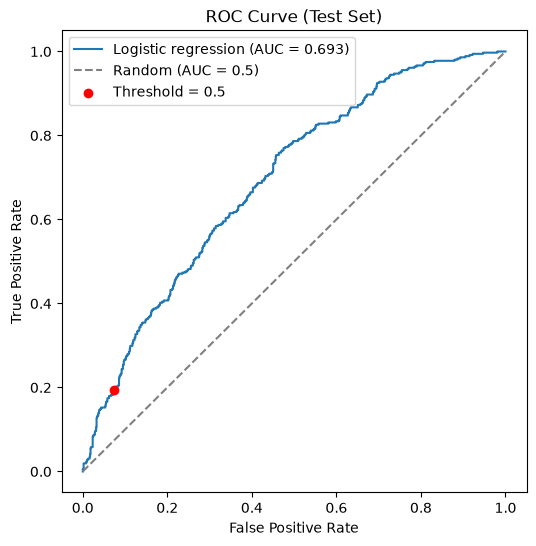

In [23]:
plt.figure(figsize=(6, 6))
plt.plot(fpr_curve, tpr_curve, label=f'Logistic regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random (AUC = 0.5)')
plt.scatter(fpr, tpr, color='red', zorder=3, label='Threshold = 0.5')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Test Set)')
plt.legend()
plt.show()

The test-set AUC is 0.693: a randomly chosen depressed student receives a higher predicted probability than a randomly chosen non-depressed student 69% of the time. Ranking ability is moderate and clearly better than random (0.5). The 0.5 threshold sits near the lower-left of the curve (TPR = 0.19, FPR = 0.07), so lowering the threshold can capture substantially more depressed students at the cost of more false positives.

### AUC Is Invariant to Monotonic Transformations
AUC depends only on the *ranking* of predictions. Any strictly increasing transformation (e.g., logit, odds) preserves the ranking, so AUC stays the same.

In [24]:
pred_logit_test = np.log(pred_prob_test / (1 - pred_prob_test))
pred_odds_test = np.exp(pred_logit_test)

In [25]:
print('AUC (probability):', round(roc_auc_score(y_test, pred_prob_test), 4))
print('AUC (logit):      ', round(roc_auc_score(y_test, pred_logit_test), 4))
print('AUC (odds):       ', round(roc_auc_score(y_test, pred_odds_test), 4))

AUC (probability): 0.6931
AUC (logit):       0.6931
AUC (odds):        0.6931


AUC is identical (0.6931) for probabilities, logits, and odds. Because logit and odds are strictly increasing functions of the probability, they preserve the ordering of students, and AUC only depends on that ordering.

## Calibration Curve
AUC measures ranking; calibration measures whether predicted probabilities match observed frequencies. For a well-calibrated model, among students with a predicted probability of about 0.3, roughly 30% should actually be depressed.

In [26]:
from sklearn.calibration import calibration_curve

In [27]:
prob_true, prob_pred = calibration_curve(y_test, pred_prob_test, n_bins=10, strategy='quantile')

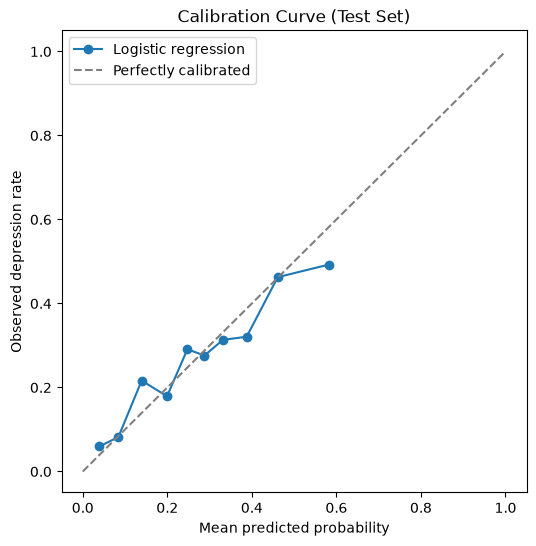

In [28]:
plt.figure(figsize=(6, 6))
plt.plot(prob_pred, prob_true, marker='o', label='Logistic regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfectly calibrated')
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed depression rate')
plt.title('Calibration Curve (Test Set)')
plt.legend()
plt.show()

The model is reasonably well calibrated: across most bins, the observed depression rate is within about 0.05 of the mean predicted probability, consistent with sampling noise at ~134 students per bin. The highest-risk bin is slightly overestimated (predicted 0.58 vs. observed 0.49). Predicted probabilities rarely exceed 0.6, reflecting the model's moderate discriminative power.

Good calibration matters for the next step: the cost-based optimal threshold assumes predicted probabilities can be read as true probabilities.

## Cost-Based Threshold Selection
Assume a false negative (missing a depressed student) costs 4 times as much as a false positive (an unnecessary counseling contact): C_FP = 1, C_FN = 4.

For a student with predicted probability *p*, contacting is worthwhile when the expected cost of not contacting exceeds that of contacting:

p × C_FN > (1 − p) × C_FP  ⟹  p > C_FP / (C_FP + C_FN) = 0.2

In [29]:
C_FP, C_FN = 1, 4
theoretical_threshold = C_FP / (C_FP + C_FN)

In [30]:
threshold_grid = np.arange(0.05, 0.65, 0.01)
costs = []
for t in threshold_grid:
    pred_t = (pred_prob_test >= t).astype(int)
    fp_t = ((pred_t == 1) & (y_test == 0)).sum()
    fn_t = ((pred_t == 0) & (y_test == 1)).sum()
    costs.append(C_FP * fp_t + C_FN * fn_t)

In [31]:
costs = np.array(costs)
best_threshold = threshold_grid[costs.argmin()]

In [32]:
print('Theoretical threshold:', theoretical_threshold)
print('Empirical best threshold (test):', round(best_threshold, 2))

Theoretical threshold: 0.2
Empirical best threshold (test): 0.13


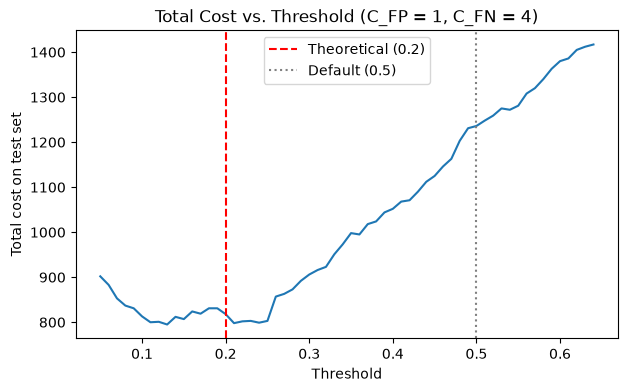

In [33]:
plt.figure(figsize=(7, 4))
plt.plot(threshold_grid, costs)
plt.axvline(theoretical_threshold, color='red', linestyle='--', label=f'Theoretical ({theoretical_threshold})')
plt.axvline(0.5, color='gray', linestyle=':', label='Default (0.5)')
plt.xlabel('Threshold')
plt.ylabel('Total cost on test set')
plt.title(f'Total Cost vs. Threshold (C_FP = {C_FP}, C_FN = {C_FN})')
plt.legend()
plt.show()

In [34]:
def evaluate(threshold):
    pred = (pred_prob_test >= threshold).astype(int)
    tp = ((pred == 1) & (y_test == 1)).sum()
    tn = ((pred == 0) & (y_test == 0)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    fn = ((pred == 0) & (y_test == 1)).sum()
    return {
        'threshold': threshold,
        'accuracy': round((tp + tn) / len(y_test), 4),
        'TPR': round(tp / (tp + fn), 4),
        'FPR': round(fp / (fp + tn), 4),
        'n_contacted': tp + fp,
        'total_cost': C_FP * fp + C_FN * fn
    }

pd.DataFrame([evaluate(0.5), evaluate(theoretical_threshold)])

,threshold,accuracy,TPR,FPR,n_contacted,total_cost
0,0.5,0.7291,0.1939,0.0735,142,1236
1,0.2,0.5261,0.8310,0.5863,874,818


The total cost curve is flat between thresholds of roughly 0.11 and 0.25. The empirical minimum on the test set (0.13) and the theoretical threshold (0.2) yield nearly identical costs (within 3%); differences inside this range reflect sampling noise. The empirical minimum is shown only to validate the theoretical threshold, which is derived from costs alone and does not use test data.

Compared with the default 0.5 threshold, the cost-based threshold reduces total cost by 34% (1,236 → 818) by raising TPR from 19% to 83%. Accuracy drops from 0.73 to 0.53, illustrating that accuracy treats all errors equally and is a poor objective when error costs are asymmetric.

However, a 0.2 threshold flags 65% of students for outreach. If counseling capacity is limited, the decision becomes choosing *which* students to contact given a fixed budget, which is addressed next.

## Top-k Selection vs. Random Selection
Suppose the counseling center can only contact k% of students. Compare two strategies:
- **Model-based**: contact the k% of students with the highest predicted probability.
- **Random**: contact k% of students at random; the expected number of depressed students reached is k% × total depressed.

Lift = depressed students reached by the model / expected number reached by random selection.

In [35]:
n_test = len(y_test)
n_depressed = y_test.sum()
order = pred_prob_test.sort_values(ascending=False).index

In [36]:
rows = []
for k in [0.05, 0.10, 0.20, 0.30, 0.50]:
    n_contact = int(round(k * n_test))
    top_k_idx = order[:n_contact]
    model_hits = y_test.loc[top_k_idx].sum()
    random_hits = k * n_depressed
    rows.append({
        'k': f'{int(k * 100)}%',
        'n_contacted': n_contact,
        'model_hits': model_hits,
        'random_hits (expected)': round(random_hits, 1),
        'model_precision': round(model_hits / n_contact, 4),
        'lift': round(model_hits / random_hits, 2)
    })

topk_table = pd.DataFrame(rows)
topk_table

,k,n_contacted,model_hits,random_hits (expected),model_precision,lift
0,5%,67,36,18.0,0.5373,1.99
1,10%,134,66,36.1,0.4925,1.83
2,20%,268,128,72.2,0.4776,1.77
3,30%,402,171,108.3,0.4254,1.58
4,50%,670,250,180.5,0.3731,1.39


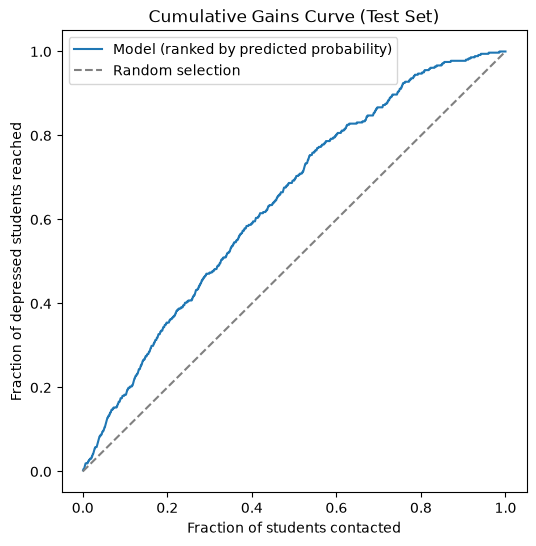

In [37]:
sorted_y = y_test.loc[order].values
cum_hits = np.cumsum(sorted_y) / n_depressed
frac_contacted = np.arange(1, n_test + 1) / n_test

plt.figure(figsize=(6, 6))
plt.plot(frac_contacted, cum_hits, label='Model (ranked by predicted probability)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random selection')
plt.xlabel('Fraction of students contacted')
plt.ylabel('Fraction of depressed students reached')
plt.title('Cumulative Gains Curve (Test Set)')
plt.legend()
plt.show()